In [2]:
import os
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print(device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

cuda
NVIDIA GeForce RTX 4090


In [4]:
#Import SAM2
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("SAM2 imported successfully")

SAM2 imported successfully


In [5]:
#Find SAM2 checkpoint
possible_checkpoints = [
    "/home/zahranadeem/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2_repo/checkpoints/sam2_hiera_small.pt",
]

checkpoint = None

for p in possible_checkpoints:
    if os.path.exists(p):
        checkpoint = p
        break

print("Checkpoint:", checkpoint)

assert checkpoint is not None, "SAM2 checkpoint not found"

Checkpoint: /home/zahranadeem/checkpoints/sam2_hiera_small.pt


In [6]:
#Load SAM2 
config = "sam2_hiera_s.yaml"

sam2_model = build_sam2(
    config,
    checkpoint,
    device=device
)

predictor = SAM2ImagePredictor(sam2_model)

print("SAM2 loaded successfully")

SAM2 loaded successfully


In [10]:
#Load VegANN
from datasets import load_dataset
dataset = load_dataset(
            "simonMadec/VegAnn"
)

print(dataset)
print(dataset["train"][10].keys())

DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])


In [13]:
#Loading one sample of VegAnn
idx = 10

sample = dataset["train"][idx]

image = np.array(sample["image"])
mask = np.array(sample["mask"])

# VegAnn: vegetation = 0, background = 255
gt_mask = mask == 0

print("Image shape:", image.shape)
print("Mask values:", np.unique(mask))
print("GT pixels:", gt_mask.sum())
print("Species:", sample["Species"])

Image shape: (512, 512, 3)
Mask values: [  0 255]
GT pixels: 48637
Species: Mix


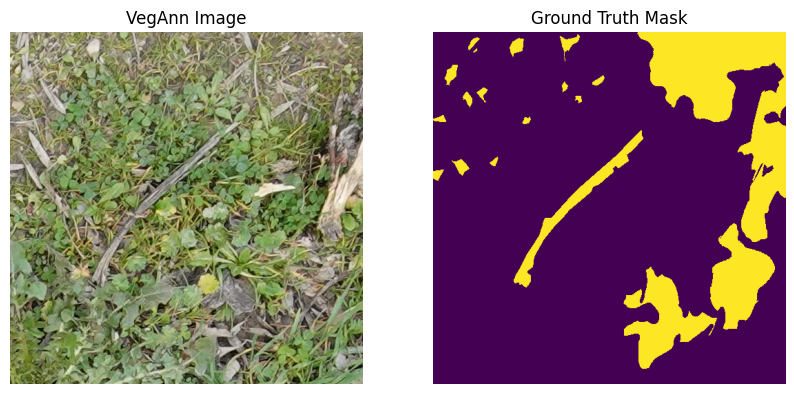

In [14]:
#Visualize Image and GT mask
plt.figure(figsize=(10,5))

plt.subplot(121)
plt.imshow(image)
plt.title("VegAnn Image")
plt.axis("off")

plt.subplot(122)
plt.imshow(gt_mask)
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [15]:
#Loading AGRICLIP 
agriclip_paths = [
    "/home/zahranadeem/AgriCLIP",
    "/home/zahranadeem/AgriCLIP/AgriCLIP_alignment",
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP",
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment",
]

for p in agriclip_paths:
    if os.path.exists(p) and p not in sys.path:
        sys.path.append(p)

print("Paths added")

Paths added


In [16]:
#Import AgriCLIP modules 
from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("AgriCLIP modules imported")

AgriCLIP modules imported


In [17]:
#Loading DINO 
model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True
)

dino_path_candidates = [
    "/home/zahranadeem/AgriCLIP/Weights/dino_pretrain.pth",
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/Weights/dino_pretrain.pth",
]

dino_path = None

for p in dino_path_candidates:
    if os.path.exists(p):
        dino_path = p
        break

print("DINO path:", dino_path)

model.load_state_dict(
    torch.load(dino_path, map_location="cpu")
)

model = model.to(device)
model.eval()

def forward_features(x):
    return model(x)

model.forward_features = forward_features

print("DINO loaded")

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DINO path: /home/zahranadeem/AgriCLIP/Weights/dino_pretrain.pth
DINO loaded


In [18]:
#Load Fine tuned AgriCLIP aligner 
text_to_concept = TextToConcept(model, "Dino")

aligner_path = "/home/zahranadeem/thesis/vegann_plantvillage_aligner.pth"

text_to_concept.load_linear_aligner(aligner_path)

print("VegAnn + PlantVillage fine-tuned aligner loaded")

VegAnn + PlantVillage fine-tuned aligner loaded


In [19]:
#AgriCLIP species prediction 
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

species_list = sorted(list(set(dataset["train"]["Species"])))

species_classifier = text_to_concept.get_zero_shot_classifier(
    species_list,
    prompts=[
        "An agricultural image showing {} plants."
    ]
)

img_tensor = transform(sample["image"]).unsqueeze(0).to(device)

with torch.no_grad():
    logits = species_classifier(img_tensor)

scores = logits.squeeze().cpu().numpy()

top5 = np.argsort(scores)[-5:][::-1]

print("Ground Truth:", sample["Species"])
print("\nAgriCLIP Top-5:")

for i in top5:
    print(species_list[i], scores[i])

predicted_species = species_list[top5[0]]

print("\nPredicted species:", predicted_species)

Ground Truth: Mix

AgriCLIP Top-5:
Na 0.6270458
Bean 0.621731
Potato 0.61963564
Mix 0.6140789
Tabacco 0.61375505

Predicted species: Na


In [20]:
#Creating automatic vegetation box without GT 
#Image itself is used to estimate vegetation location, while 
#Agriclip supplies the semantic label
from scipy import ndimage

def get_vegetation_box_from_image(image, padding=10):
    """
    Automatic vegetation localization using Excess Green index.
    This does NOT use the ground-truth mask.
    """
    
    img = image.astype(np.float32) / 255.0

    r = img[:,:,0]
    g = img[:,:,1]
    b = img[:,:,2]

    exg = 2*g - r - b

    threshold = np.percentile(exg, 70)

    veg_mask = exg > threshold

    labeled, num = ndimage.label(veg_mask)

    if num == 0:
        H, W = image.shape[:2]
        return np.array([
            W//4,
            H//4,
            3*W//4,
            3*H//4
        ]), veg_mask

    sizes = ndimage.sum(
        veg_mask,
        labeled,
        range(1, num+1)
    )

    largest_label = np.argmax(sizes) + 1

    largest_mask = labeled == largest_label

    ys, xs = np.where(largest_mask)

    H, W = image.shape[:2]

    x1 = max(xs.min() - padding, 0)
    y1 = max(ys.min() - padding, 0)
    x2 = min(xs.max() + padding, W-1)
    y2 = min(ys.max() + padding, H-1)

    box = np.array([x1, y1, x2, y2])

    return box, largest_mask

In [21]:
#Generate AgriCLIP guided SAM2 box 

agriclip_box, estimated_veg_mask = get_vegetation_box_from_image(image)

print("AgriCLIP semantic label:", predicted_species)
print("Generated SAM2 box:", agriclip_box)

AgriCLIP semantic label: Na
Generated SAM2 box: [148 119 437 420]


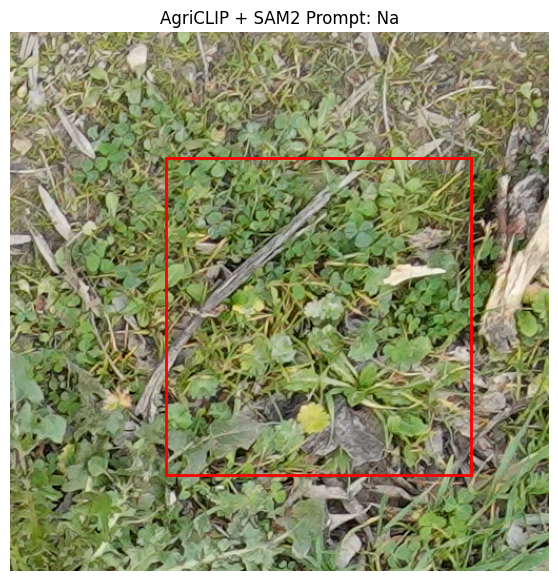

In [22]:
#Visualize the generated box 
import matplotlib.patches as patches

x1, y1, x2, y2 = agriclip_box

fig, ax = plt.subplots(figsize=(7,7))

ax.imshow(image)

rect = patches.Rectangle(
    (x1, y1),
    x2-x1,
    y2-y1,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(rect)

ax.set_title(f"AgriCLIP + SAM2 Prompt: {predicted_species}")
ax.axis("off")

plt.show()

In [23]:
#Running SAM2 with AgriCLIP generated box 

predictor.set_image(image)

masks, scores, logits = predictor.predict(
    box=agriclip_box,
    multimask_output=True
)

best_idx = scores.argmax()

agriclip_sam2_mask = masks[best_idx] > 0

print("Best SAM2 score:", scores[best_idx])
print("Pred pixels:", agriclip_sam2_mask.sum())

Best SAM2 score: 0.3431112
Pred pixels: 4725


In [24]:
#IoU and Dice function 

def compute_iou_dice(pred_mask, gt_mask):
    
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    iou = intersection / union if union > 0 else 0

    dice = (
        2 * intersection
    ) / (
        pred.sum() + gt.sum()
    ) if (pred.sum() + gt.sum()) > 0 else 0

    return iou, dice, intersection


In [46]:
#Evaluate AgriCLIP + SAM2
agriclip_iou, agriclip_dice, intersection = compute_iou_dice(
    agriclip_sam2_mask,
    gt_mask
)

print("Intersection:", intersection)
print(f"AgriCLIP + SAM2 IoU: {agriclip_iou*100:.2f}%")
print(f"AgriCLIP + SAM2 Dice: {agriclip_dice*100:.2f}%")

Intersection: 4376
AgriCLIP + SAM2 IoU: 8.93%
AgriCLIP + SAM2 Dice: 16.40%


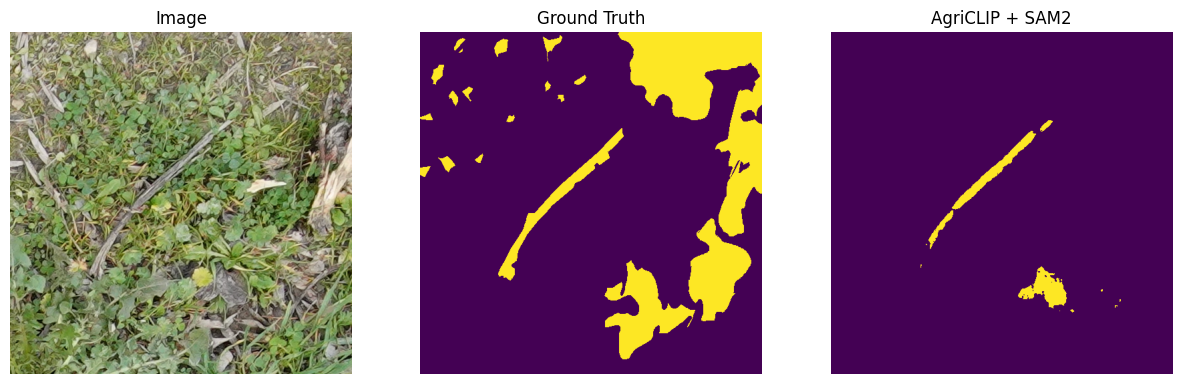

In [33]:
#Vosualize Final result 

plt.figure(figsize=(15,5))

plt.subplot(131)
plt.imshow(image)
plt.title("Image")
plt.axis("off")

plt.subplot(132)
plt.imshow(gt_mask)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(133)
plt.imshow(agriclip_sam2_mask)
plt.title("AgriCLIP + SAM2")
plt.axis("off")

plt.show()

In [47]:
#Comparsion with previous baselines 

results = pd.DataFrame({
    "Method": [
        "SAM2 + Point Prompt",
        "SAM2 + GT Box Prompt",
        "AgriCLIP + SAM2 Box"
    ],
    "IoU": [
        0.5211705490116961,
        0.8671463226660736,
        agriclip_iou
    ],
    "Dice": [
        0.6852230334728745,
        0.9288466706003917,
        agriclip_dice
    ]
})

results

results_display = results.copy()

results_display["IoU"] = results_display["IoU"].apply(lambda x: f"{x*100:.2f}%")
results_display["Dice"] = results_display["Dice"].apply(lambda x: f"{x*100:.2f}%")

results_display

,Method,IoU,Dice
0,SAM2 + Point Prompt,52.12%,68.52%
1,SAM2 + GT Box Prompt,86.71%,92.88%
2,AgriCLIP + SAM2 Box,8.93%,16.40%


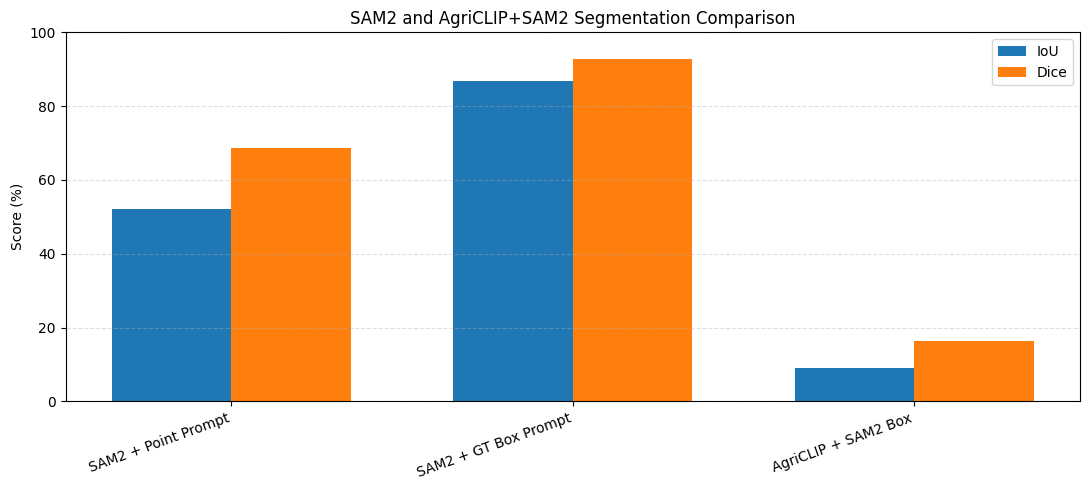

In [39]:
#Plot Comparsion 

iou_scores = [x * 100 for x in results["IoU"].tolist()]
dice_scores = [x * 100 for x in results["Dice"].tolist()]
methods = results["Method"].tolist()
iou_scores = results["IoU"].tolist()
dice_scores = results["Dice"].tolist()

x = np.arange(len(methods))
width = 0.35

plt.figure(figsize=(11,5))

plt.bar(
    x - width/2,
    iou_scores,
    width,
    label="IoU"
)

plt.bar(
    x + width/2,
    dice_scores,
    width,
    label="Dice"
)

plt.xticks(
    x,
    methods,
    rotation=20,
    ha="right"
)

plt.ylabel("Score (%)")
plt.title("SAM2 and AgriCLIP+SAM2 Segmentation Comparison")
plt.ylim(0,100)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(
    "agriclip_sam2_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()